# 3.1 Obtenció i descripció de les dades

In [1]:
#Importar mòduls
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
#Importar dades i llegir-les
train=pd.read_csv('/content/drive/MyDrive/TR Marc Magdaleno/train.csv')
train

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8688,9276_01,Europa,False,A/98/P,55 Cancri e,41.0,True,0.0,6819.0,0.0,1643.0,74.0,Gravior Noxnuther,False
8689,9278_01,Earth,True,G/1499/S,PSO J318.5-22,18.0,False,0.0,0.0,0.0,0.0,0.0,Kurta Mondalley,False
8690,9279_01,Earth,False,G/1500/S,TRAPPIST-1e,26.0,False,0.0,0.0,1872.0,1.0,0.0,Fayey Connon,True
8691,9280_01,Europa,False,E/608/S,55 Cancri e,32.0,False,0.0,1049.0,0.0,353.0,3235.0,Celeon Hontichre,False


Cada **fila** és un passatger i les **columnes** són diferents tipus de dades que seran favorables a l'hora de fer les nostres prediccions.

# 3.2 Exploració inicial de les dades

In [3]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   object 
 1   HomePlanet    8492 non-null   object 
 2   CryoSleep     8476 non-null   object 
 3   Cabin         8494 non-null   object 
 4   Destination   8511 non-null   object 
 5   Age           8514 non-null   float64
 6   VIP           8490 non-null   object 
 7   RoomService   8512 non-null   float64
 8   FoodCourt     8510 non-null   float64
 9   ShoppingMall  8485 non-null   float64
 10  Spa           8510 non-null   float64
 11  VRDeck        8505 non-null   float64
 12  Name          8493 non-null   object 
 13  Transported   8693 non-null   bool   
dtypes: bool(1), float64(6), object(7)
memory usage: 891.5+ KB


In [4]:
train.describe()

,Age,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck
count,8514.000000,8512.000000,8510.000000,8485.000000,8510.000000,8505.000000
mean,28.827930,224.687617,458.077203,173.729169,311.138778,304.854791
std,14.489021,666.717663,1611.489240,604.696458,1136.705535,1145.717189
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,19.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,27.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,38.000000,47.000000,76.000000,27.000000,59.000000,46.000000
max,79.000000,14327.000000,29813.000000,23492.000000,22408.000000,24133.000000


<Axes: xlabel='HomePlanet', ylabel='Count'>

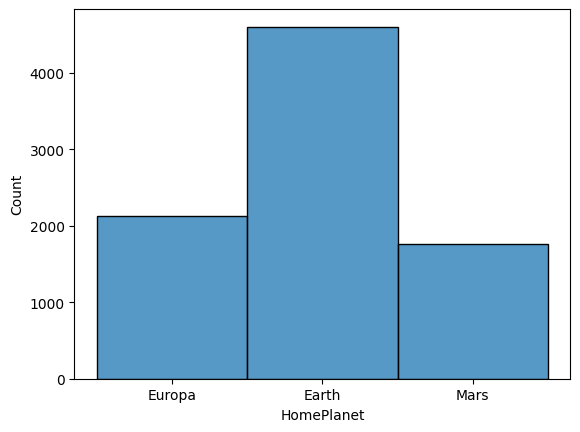

In [5]:
sns.histplot(train['HomePlanet'])

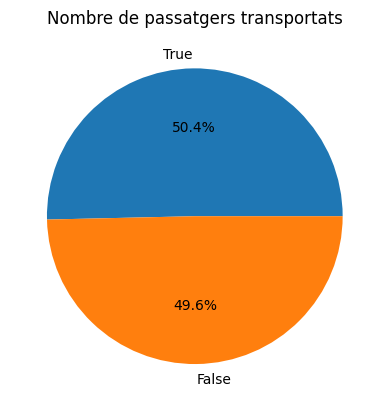

In [6]:
train["Transported"].value_counts(normalize=True).plot(
    kind="pie",
    autopct="%1.1f%%",
    )
plt.ylabel("")
plt.title("Nombre de passatgers transportats")
plt.show()

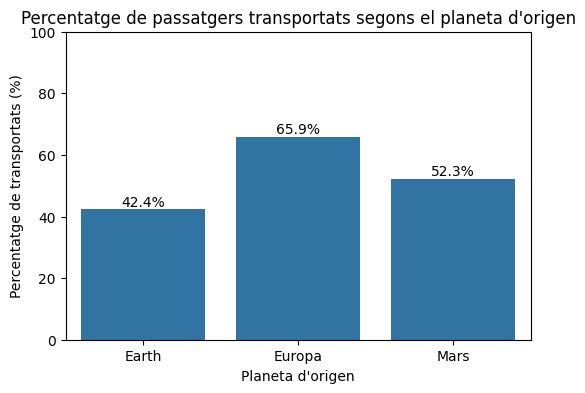

In [7]:
# Calcular el percentatge de transportats per planeta
percentatges = (
    train.groupby("HomePlanet")["Transported"]
    .mean()
    .mul(100)
    .reset_index()
)

percentatges.columns = ["HomePlanet", "Percentatge"]

# Crear el gràfic
plt.figure(figsize=(6,4))
ax = sns.barplot(data=percentatges, x="HomePlanet", y="Percentatge")

# Afegir el percentatge sobre cada barra
for i, v in enumerate(percentatges["Percentatge"]):
    ax.text(i, v + 1, f"{v:.1f}%", ha="center")

plt.title("Percentatge de passatgers transportats segons el planeta d'origen")
plt.xlabel("Planeta d'origen")
plt.ylabel("Percentatge de transportats (%)")
plt.ylim(0, 100)

plt.show()

(0.0, 100.0)

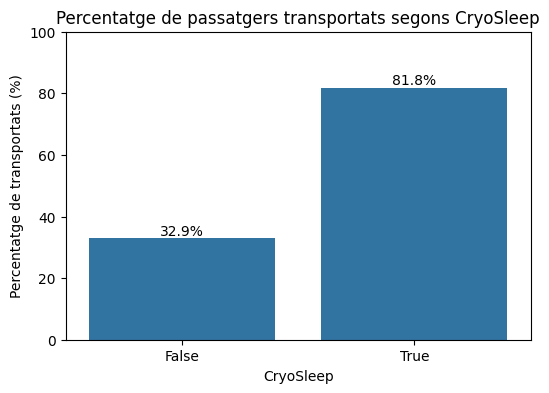

In [8]:
percentatges = (
    train.groupby("CryoSleep")["Transported"]
    .mean()
    .mul(100)
    .reset_index()
    )

percentatges.columns = ["CryoSleep", "Percentatge"]

plt.figure(figsize=(6,4))
ax = sns.barplot(data=percentatges, x="CryoSleep", y="Percentatge")

for i, v in enumerate(percentatges["Percentatge"]):
    ax.text(i, v + 1, f"{v:.1f}%", ha="center")

plt.title("Percentatge de passatgers transportats segons CryoSleep")
plt.xlabel("CryoSleep")
plt.ylabel("Percentatge de transportats (%)")
plt.ylim(0, 100)

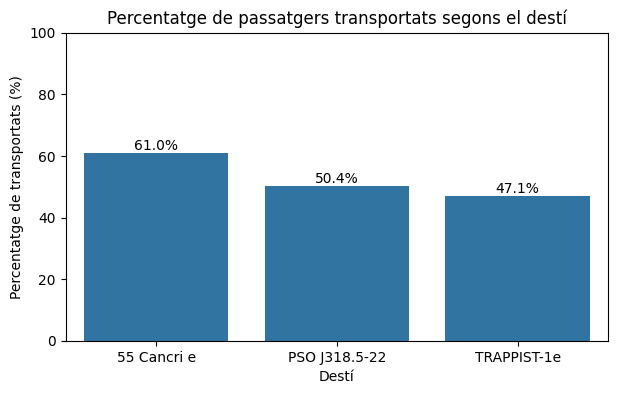

In [9]:
percentatges = (
    train.groupby("Destination")["Transported"]
    .mean()
    .mul(100)
    .reset_index()
)

percentatges.columns = ["Destination", "Percentatge"]

plt.figure(figsize=(7,4))
ax = sns.barplot(data=percentatges, x="Destination", y="Percentatge")

for i, v in enumerate(percentatges["Percentatge"]):
    ax.text(i, v + 1, f"{v:.1f}%", ha="center")

plt.title("Percentatge de passatgers transportats segons el destí")
plt.xlabel("Destí")
plt.ylabel("Percentatge de transportats (%)")
plt.ylim(0, 100)
plt.show()

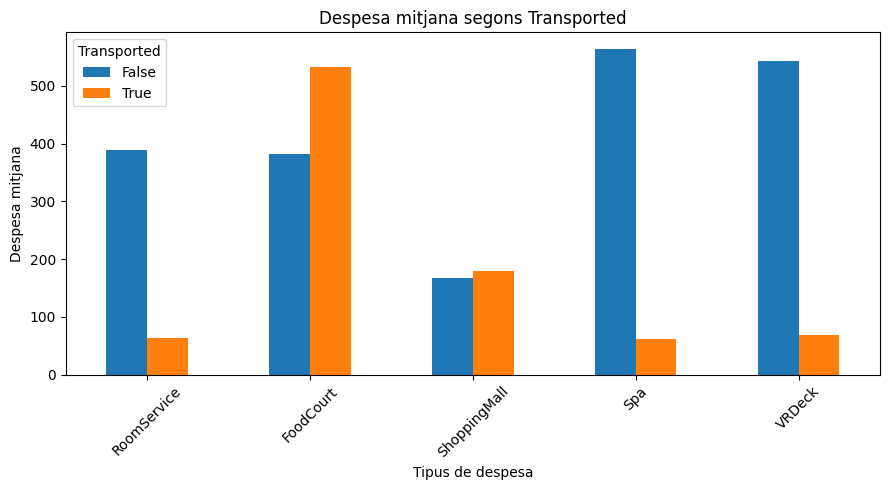

In [10]:
despeses = ["RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck"]

mitjanes = train.groupby("Transported")[despeses].mean().T

mitjanes.plot(kind="bar", figsize=(9,5))

plt.title("Despesa mitjana segons Transported")
plt.xlabel("Tipus de despesa")
plt.ylabel("Despesa mitjana")
plt.xticks(rotation=45)
plt.legend(title="Transported")
plt.tight_layout()
plt.show()

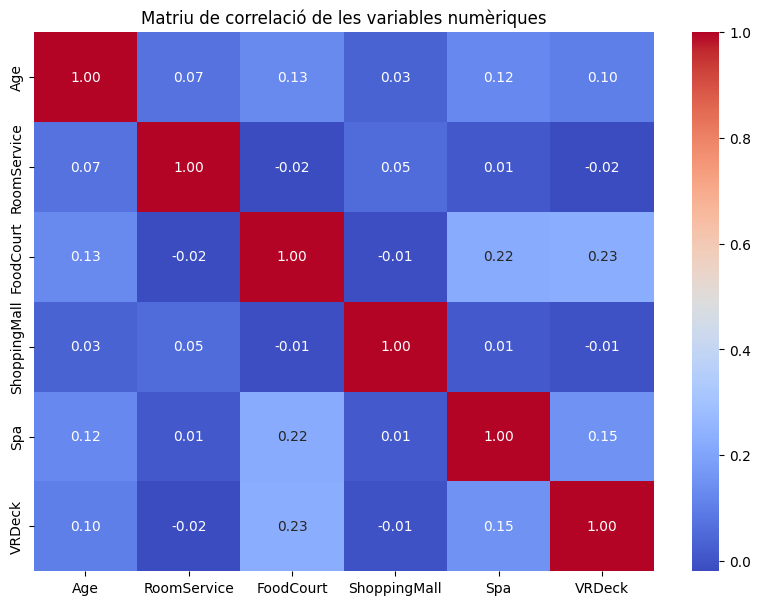

In [11]:
correlacions = train.select_dtypes(include="number").corr()

plt.figure(figsize=(10,7))

sns.heatmap(correlacions, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Matriu de correlació de les variables numèriques")
plt.show()

# 3.3 Preparació i neteja de dades

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

In [13]:
#Eliminem PassengerId i els noms
train = train.drop(columns=["PassengerId"])
train = train.drop(columns=["Name"])

In [14]:
# Comprovem quants valors buits hi ha a cada columna
train.isnull().sum()

,0
HomePlanet,201
CryoSleep,217
Cabin,199
Destination,182
Age,179
VIP,203
RoomService,181
FoodCourt,183
ShoppingMall,208
Spa,183


In [15]:
# Omlim els forats buits de les columnes numèriques
columnes_numeriques= ["Age",
                      "RoomService",
                      "FoodCourt",
                      "ShoppingMall",
                      "Spa",
                      "VRDeck"
                      ]
for columna in columnes_numeriques:
  train[columna]=train[columna].fillna(train[columna].median())

Fem servir la **mediana** de la columna numèrica per omplir els buits que hi havien a la columna.
Es fa servir perquè si es fes servir la mitjana aritmètica i hi hagués algun valor molt extrem als altres, la mitjana de la columna podria ser distorsionada.

Per exemple la *Food Court*, on més del 50% de les persones no han gastat res, pero després hi ha algú que ha arribat a gastar gairebé 30.000$.

In [16]:
train.isnull().sum()

,0
HomePlanet,201
CryoSleep,217
Cabin,199
Destination,182
Age,0
VIP,203
RoomService,0
FoodCourt,0
ShoppingMall,0
Spa,0


In [17]:
# Extraiem la coberta de la cabina
train["Deck"] = train["Cabin"].str.split("/").str[0]

# Eliminem la columna Cabin original
train = train.drop(columns=["Cabin"])

# Omplim els valors buits de Deck
train["Deck"] = train["Deck"].fillna(train["Deck"].mode()[0])

In [18]:
train.isnull().sum()

,0
HomePlanet,201
CryoSleep,217
Destination,182
Age,0
VIP,203
RoomService,0
FoodCourt,0
ShoppingMall,0
Spa,0
VRDeck,0


In [19]:
# Comprovem les columnes del dataset (les columnes i el tipus de variable)
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   HomePlanet    8492 non-null   object 
 1   CryoSleep     8476 non-null   object 
 2   Destination   8511 non-null   object 
 3   Age           8693 non-null   float64
 4   VIP           8490 non-null   object 
 5   RoomService   8693 non-null   float64
 6   FoodCourt     8693 non-null   float64
 7   ShoppingMall  8693 non-null   float64
 8   Spa           8693 non-null   float64
 9   VRDeck        8693 non-null   float64
 10  Transported   8693 non-null   bool   
 11  Deck          8693 non-null   object 
dtypes: bool(1), float64(6), object(5)
memory usage: 755.7+ KB


In [20]:
# Mostrem les primeres files del dataset preparat
train.head()

,HomePlanet,CryoSleep,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported,Deck
0,Europa,False,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,False,B
1,Earth,False,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,True,F
2,Europa,False,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,False,A
3,Europa,False,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,False,A
4,Earth,False,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,True,F


In [21]:
# Anàlisi de correlacions

#correlation_matrix = train.corr()
#correlation_matrix

#plt.figure(figsize=(14,12))
#plt.title('Pearson Correlation of Features', y=1.05, size=15)
#sns.heatmap(correlation_matrix);

Ara separarem les dades per l'entrenament dels models i acabarem d'omplir els valors buits.

In [22]:
#Separem les dades i la variable que volem adivindar.
x = train.drop(columns=["Transported"])
y = train["Transported"]

In [23]:
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)

In [24]:
# Definim les columnes numèriques
columnes_numeriques = [
    "Age",
    "RoomService",
    "FoodCourt",
    "ShoppingMall",
    "Spa",
    "VRDeck"]

# Definim les columnes categòriques
columnes_categoriques = [
    "HomePlanet",
    "CryoSleep",
    "Destination",
    "VIP",
    "Deck"]

In [25]:
# SimpleImputer
# StandardScaler
# OneHotEncoder

preparacio_numerica = Pipeline(steps=[("imputacio", SimpleImputer(strategy="median")),
                                      ("escalat", StandardScaler())])

preparacio_categorica = Pipeline(steps=[("imputacio", SimpleImputer(strategy="most_frequent")),
                                        ("binaritzacio", OneHotEncoder(handle_unknown="ignore"))])

In [26]:
preprocessament = ColumnTransformer(
    transformers=[
        ("numeriques", preparacio_numerica, columnes_numeriques),
        ("categoriques", preparacio_categorica, columnes_categoriques)])
x_train = preprocessament.fit_transform(x_train)
x_test = preprocessament.transform(x_test)

# 3.4 Entrenament dels models

Volem predir la variable **Transported**, la qual es una boolean (només pot ser "True" o "False").

In [27]:
#Importem les eines necessàries per veure els resultats gràficament
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

## Models

### Regressió logística

In [28]:
# Importem el model
from sklearn.linear_model import LogisticRegression
# Creem el model
model_regressio = LogisticRegression(max_iter=1000)
# Entrenem el model amb les dades de l'entrenament
model_regressio.fit(x_train, y_train)
# Fem prediccions amb les dades de prova (les guardem a la variable)
prediccions_regressio = model_regressio.predict(x_test)

prediccions_regressio[:10]

array([ True,  True, False,  True, False,  True,  True,  True, False,
        True])

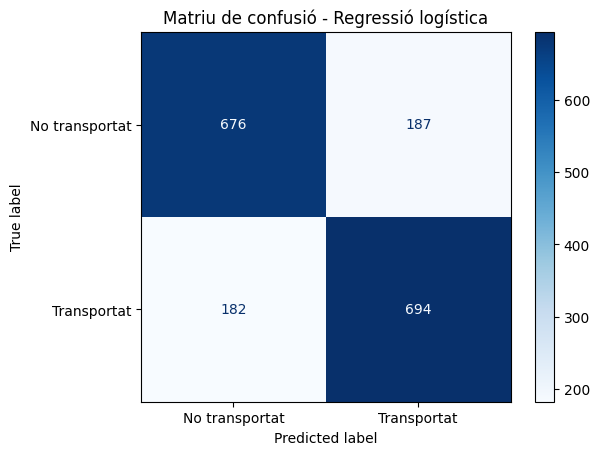

In [29]:
# Calculem la matriu de confusió
matriu = confusion_matrix(y_test, prediccions_regressio)
visualitzacio = ConfusionMatrixDisplay(
    confusion_matrix=matriu,
    display_labels=["No transportat", "Transportat"])

visualitzacio.plot(cmap="Blues")
plt.title("Matriu de confusió - Regressió logística")
plt.show()

### Arbres de decisió

In [30]:
from sklearn.tree import DecisionTreeClassifier
# Creem el model
model_arbre = DecisionTreeClassifier(max_depth=5, random_state=42)
# Entrenem el model amb les dades de l'entrenament
model_arbre.fit(x_train, y_train)
# Fem prediccions amb les dades de prova (les guardem a la variable)
prediccions_arbres = model_arbre.predict(x_test)

prediccions_arbres[:10]

array([ True,  True, False,  True,  True,  True,  True,  True, False,
        True])

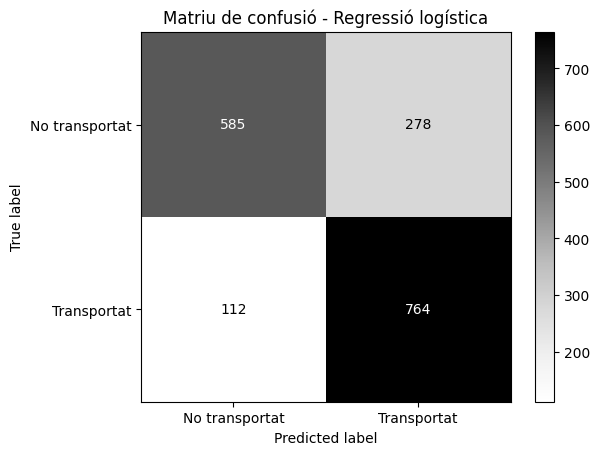

In [31]:
# Calculem la matriu de confusió
matriu = confusion_matrix(y_test, prediccions_arbres)
visualitzacio = ConfusionMatrixDisplay(
    confusion_matrix=matriu,
    display_labels=["No transportat", "Transportat"])

visualitzacio.plot(cmap="Greys")
plt.title("Matriu de confusió - Regressió logística")
plt.show()

### Random Forest

In [32]:
from sklearn.ensemble import RandomForestClassifier

model_random_forest = RandomForestClassifier(n_estimators=100,max_depth=5, random_state=42)
model_random_forest.fit(x_train, y_train)

prediccions_random_forest = model_random_forest.predict(x_test)
prediccions_random_forest[:10]

array([ True,  True, False,  True, False,  True,  True,  True, False,
        True])

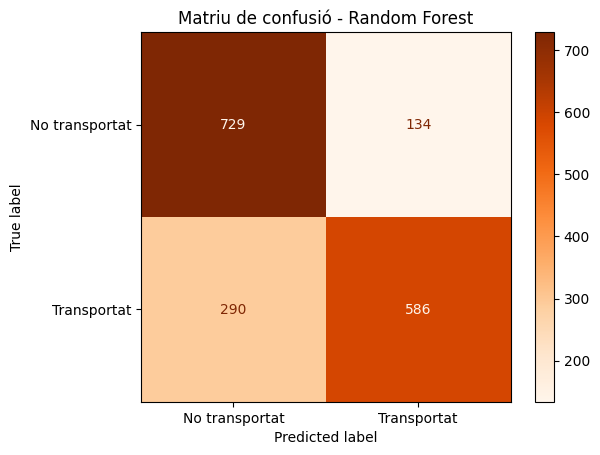

In [33]:
# Calculem la matriu de confusió
matriu = confusion_matrix(y_test, prediccions_random_forest)
visualitzacio = ConfusionMatrixDisplay(
    confusion_matrix=matriu,
    display_labels=["No transportat", "Transportat"])

visualitzacio.plot(cmap="Oranges")
plt.title("Matriu de confusió - Random Forest")
plt.show()

### KNN (K-Nearest Neighbours)

In [34]:
from sklearn.neighbors import KNeighborsClassifier

model_knn = KNeighborsClassifier(n_neighbors=5)
model_knn.fit(x_train, y_train)
prediccions_knn=model_knn.predict(x_test)

prediccions_knn[:10]

array([ True,  True, False,  True, False,  True,  True,  True, False,
        True])

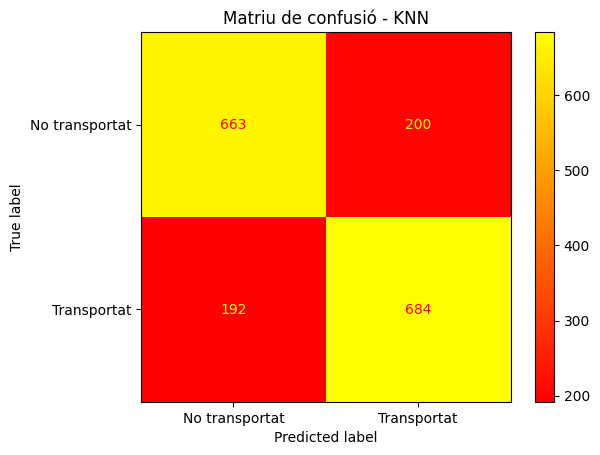

In [35]:
# Calculem la matriu de confusió
matriu = confusion_matrix(y_test, prediccions_knn)
visualitzacio = ConfusionMatrixDisplay(
    confusion_matrix=matriu,
    display_labels=["No transportat", "Transportat"])

visualitzacio.plot(cmap="autumn")
plt.title("Matriu de confusió - KNN")
plt.show()

### SVM

In [36]:
from sklearn.svm import SVC
model_svm = SVC(C=10, random_state=42)
model_svm.fit(x_train, y_train)
prediccions_svm = model_svm.predict(x_test)

prediccions_svm[:10]

array([ True,  True, False,  True, False,  True,  True,  True, False,
        True])

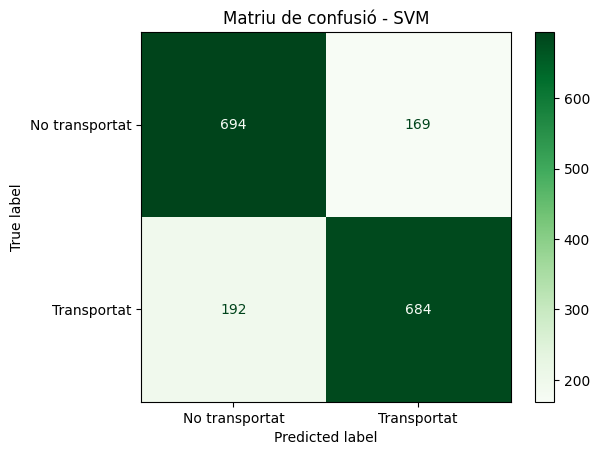

In [37]:
# Calculem la matriu de confusió
matriu = confusion_matrix(y_test, prediccions_svm)
visualitzacio = ConfusionMatrixDisplay(
    confusion_matrix=matriu,
    display_labels=["No transportat", "Transportat"])

visualitzacio.plot(cmap="Greens")
plt.title("Matriu de confusió - SVM")
plt.show()

# 3.5 Preparació dels fitxers .csv

In [38]:
# 1. Carreguem les dades originals
train_original = pd.read_csv('/content/drive/MyDrive/TR Marc Magdaleno/train.csv')
test_original = pd.read_csv('/content/drive/MyDrive/TR Marc Magdaleno/test.csv')

# Guardem els identificadors dels passatgers
passenger_ids = test_original["PassengerId"]

# 2. Preparem les dades
def preparar_dades(df):

    df = df.copy()

    # Extraiem la coberta de la cabina
    df["Deck"] = df["Cabin"].str.split("/").str[0]

    # Eliminem columnes que no utilitzarem
    df = df.drop(columns=["PassengerId", "Name", "Cabin"])

    return df

X = preparar_dades(train_original.drop(columns=["Transported"]))
y = train_original["Transported"]

X_kaggle = preparar_dades(test_original)

# 3. Preparem les dades amb el preprocessament
# que ja has definit al notebook
X_preparat = preprocessament.fit_transform(X)
X_kaggle_preparat = preprocessament.transform(X_kaggle)

# 4. Definim els cinc models
models = {"Regressio": model_regressio,
          "Arbre": model_arbre,
          "Random_Forest": model_random_forest,
          "KNN": model_knn,
          "SVM": model_svm}

# 5. Entrenem cada model amb totes les dades
# i generem un CSV per a cadascun
for nom, model in models.items():

    model.fit(X_preparat, y)

    prediccions = model.predict(X_kaggle_preparat)

    submission = pd.DataFrame({
        "PassengerId": passenger_ids,
        "Transported": prediccions})

    nom_fitxer = f"submission_{nom}.csv"

    submission.to_csv(nom_fitxer, index=False)
    print(f"Fitxer creat: {nom_fitxer}")


Fitxer creat: submission_Regressio.csv
Fitxer creat: submission_Arbre.csv
Fitxer creat: submission_Random_Forest.csv
Fitxer creat: submission_KNN.csv
Fitxer creat: submission_SVM.csv


In [39]:
# Descarreguem els fitxers .csv

from google.colab import files

files.download("submission_Regressio.csv")
files.download("submission_Arbre.csv")
files.download("submission_Random_Forest.csv")
files.download("submission_KNN.csv")
files.download("submission_SVM.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>